# Bab 3 — Dimensionality Reduction Techniques

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---


| No | Resep | Jenis | Dataset | Tujuan utama |
|----|-------|-------|---------|--------------|
| 1 | **PCA** | linear, *unsupervised* | Wine (178 × 13) | mempertahankan **varians** maksimum |
| 2 | **LDA** | linear, *supervised* | Wine | memaksimalkan **pemisahan antar-kelas** |
| 3 | **t-SNE** | non-linear, *unsupervised* | Digits (1797 × 64) | visualisasi yang mempertahankan **struktur lokal** |
| 4 | Latihan | PCA + Logistic Regression; t-SNE + K-Means | Digits | dampak reduksi dimensi pada model & clustering |


## Resep 1 — Principal Component Analysis (PCA)

### Teori
Diberikan data terpusat $\mathbf{X} \in \mathbb{R}^{n\times p}$ (setiap kolom dikurangi rata-ratanya), matriks kovarians sampelnya adalah

$$\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^\top\mathbf{X}.$$

PCA mencari arah (vektor satuan) $\mathbf{w}_1$ yang memaksimalkan varians proyeksi data:

$$\mathbf{w}_1 = \arg\max_{\lVert\mathbf{w}\rVert=1} \operatorname{Var}(\mathbf{X}\mathbf{w}) = \arg\max_{\lVert\mathbf{w}\rVert=1} \mathbf{w}^\top\mathbf{\Sigma}\mathbf{w}.$$

Dengan pengali Lagrange, solusinya memenuhi $\mathbf{\Sigma}\mathbf{w} = \lambda\mathbf{w}$ — yaitu **vektor eigen** dari $\mathbf{\Sigma}$, dan varians yang tertangkap sama dengan nilai eigennya $\lambda$. Komponen ke-2, ke-3, dst. adalah vektor eigen berikutnya (diurutkan $\lambda_1 \ge \lambda_2 \ge \dots$), dan semuanya **saling ortogonal**. Dalam praktik, scikit-learn menghitungnya lewat **SVD**: $\mathbf{X} = \mathbf{U}\mathbf{S}\mathbf{V}^\top$, dengan kolom $\mathbf{V}$ sebagai komponen utama dan $\lambda_i = s_i^2/(n-1)$.

**Explained variance ratio** komponen ke-$i$:
$$\text{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^{p}\lambda_j}$$

**Mengapa harus distandardisasi?** PCA memaksimalkan varians, sehingga fitur bersatuan besar (pada Wine, `proline` bernilai ratusan hingga ribuan) akan mendominasi komponen pertama hanya karena satuannya, bukan karena lebih informatif. Setelah standardisasi, PCA bekerja pada **matriks korelasi**.

### Persiapan — dataset Wine
178 sampel anggur dari 3 kultivar berbeda, dengan 13 fitur hasil analisis kimia.

In [ ]:
# Load libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
import warnings

# Set random seed for reproducibility and suppress warnings
np.random.seed(2024)
warnings.simplefilter(action='ignore', category=FutureWarning)

#Load dataset
wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target
display(df_wine.head(10))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


### PCA ke 2 dimensi dan visualisasi komponen

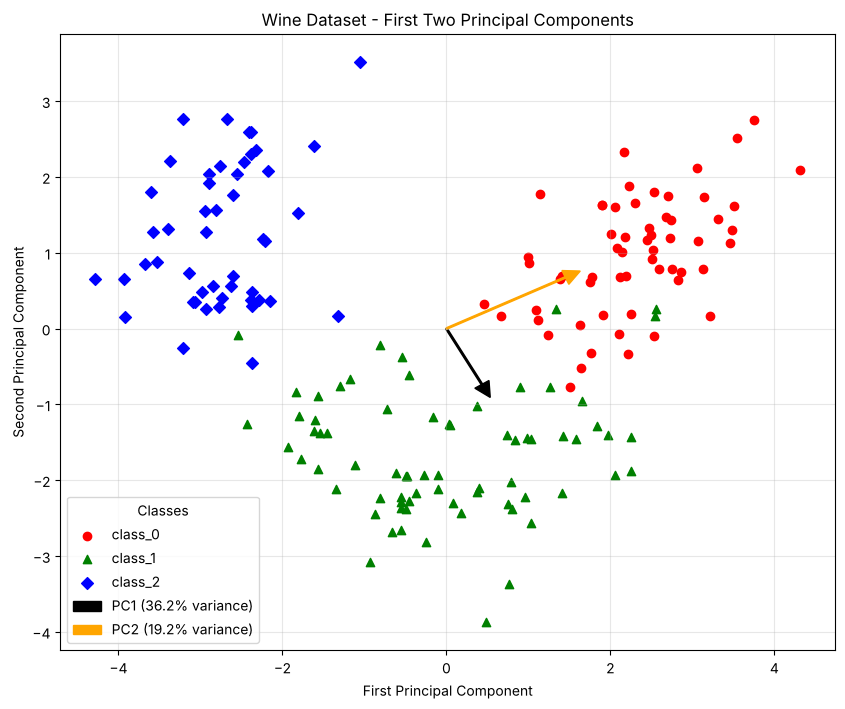

In [ ]:
# Load libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Create a pipeline for PCA
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Always scale before PCA
    ('pca', PCA(n_components=2))   # Reduce to 2 dimensions
])

# Fit and transform the data
X_pca = pca_pipeline.fit_transform(df_wine)

# Visualize the transformed data
plt.figure(figsize=(10, 8))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

# Plot the scatter points
for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1],
                c=color, marker=shape, label=wine.target_names[i])

# Get the PCA components and plot as vectors
pca = pca_pipeline.named_steps['pca']
origin = np.zeros(2)  # Origin point for vectors
arrow_colors = ['black', 'orange']

# Scale the components by their explained variance ratio for better visualization
scaling = 3
for i, (component, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(origin[0], origin[1],
              component[0] * scaling, component[1] * scaling,
              color=arrow_colors[i],
              width=0.02, head_width=0.2, head_length=0.2,
              label=f'PC{i+1} ({ratio:.1%} variance)')

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

### Explained variance ratio

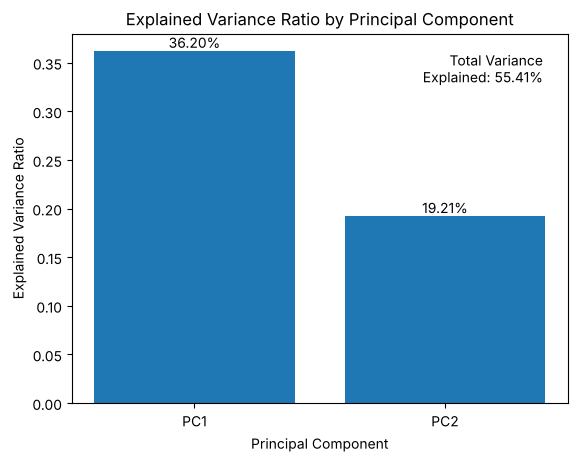

In [ ]:
# Get the explained variance ratio
pca = pca_pipeline.named_steps['pca']
explained_variance_ratio = pca.explained_variance_ratio_

# Calculate cumulative variance
cumulative_variance = np.sum(explained_variance_ratio)

# Plot barchart
fig, ax = plt.subplots()

x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

# Add percentage labels on bars
for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                        f'{height:.2%}',
                        ha='center', va='bottom')

# Add cumulative variance text in upper right
ax.text(0.95, 0.95, f'Total Variance\nExplained: {cumulative_variance:.2%}',
                transform=ax.transAxes,
                ha='right', va='top',
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

# Set custom x-axis labels for the two principal components
ax.set_xticks(x)
ax.set_xticklabels(['PC1', 'PC2'])

ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Explained Variance Ratio by Principal Component')
plt.show()

**Interpretasi.** PC1 menjelaskan sekitar **36,2%** dan PC2 sekitar **19,2%** varians data Wine yang sudah distandardisasi, total ≈ **55,4%**. Artinya proyeksi 2D ini "membuang" hampir separuh informasi varians — namun scatter plot menunjukkan ketiga kultivar sudah terpisah cukup baik di bidang PC1–PC2. Panah pada plot adalah dua komponen pertama dalam koordinat dua fitur pertama (alkohol, malic acid) yang diperbesar 3× agar terlihat.

Sel berikut memverifikasi teori di atas secara numerik: komponen PCA identik dengan vektor eigen matriks kovarians (hanya tanda +/− yang bisa berbeda, karena $\mathbf{w}$ dan $-\mathbf{w}$ sama-sama vektor eigen).

In [ ]:
# Verifikasi teori: komponen PCA = vektor eigen matriks kovarians data terstandardisasi
X_std = StandardScaler().fit_transform(df_wine)
cov = np.cov(X_std, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

print('EVR dari eigenvalue  :', (eigvals[:2] / eigvals.sum()).round(4))
print('EVR dari sklearn PCA :', pca.explained_variance_ratio_.round(4))
# vektor eigen unik hingga tanda (+/-), jadi bandingkan nilai mutlaknya
print('Komponen sama (hingga tanda):', np.allclose(np.abs(eigvecs[:, :2].T), np.abs(pca.components_)))
print('Komponen saling ortogonal   :', np.isclose(pca.components_[0] @ pca.components_[1], 0))

# Berapa komponen untuk 95% varians?
cum = np.cumsum(eigvals) / eigvals.sum()
print('Jumlah komponen untuk >= 95% varians:', np.argmax(cum >= 0.95) + 1, 'dari', len(eigvals))

EVR dari eigenvalue  : [0.362  0.1921]
EVR dari sklearn PCA : [0.362  0.1921]
Komponen sama (hingga tanda): True
Komponen saling ortogonal   : True
Jumlah komponen untuk >= 95% varians: 10 dari 13


### PCA pada pasangan dua fitur
Sel berikut memperlihatkan PCA pada dua pasang fitur. Dengan hanya 2 fitur yang distandardisasi, matriks korelasinya berbentuk $\begin{pmatrix}1 & r\\ r & 1\end{pmatrix}$ dan vektor eigennya selalu $\frac{1}{\sqrt2}(1, 1)$ dan $\frac{1}{\sqrt2}(1, -1)$ — PCA "memutar" sumbu sebesar 45°. Jika korelasi $r$ antara dua fitur tinggi, sebagian besar varians akan terkonsentrasi di PC1.

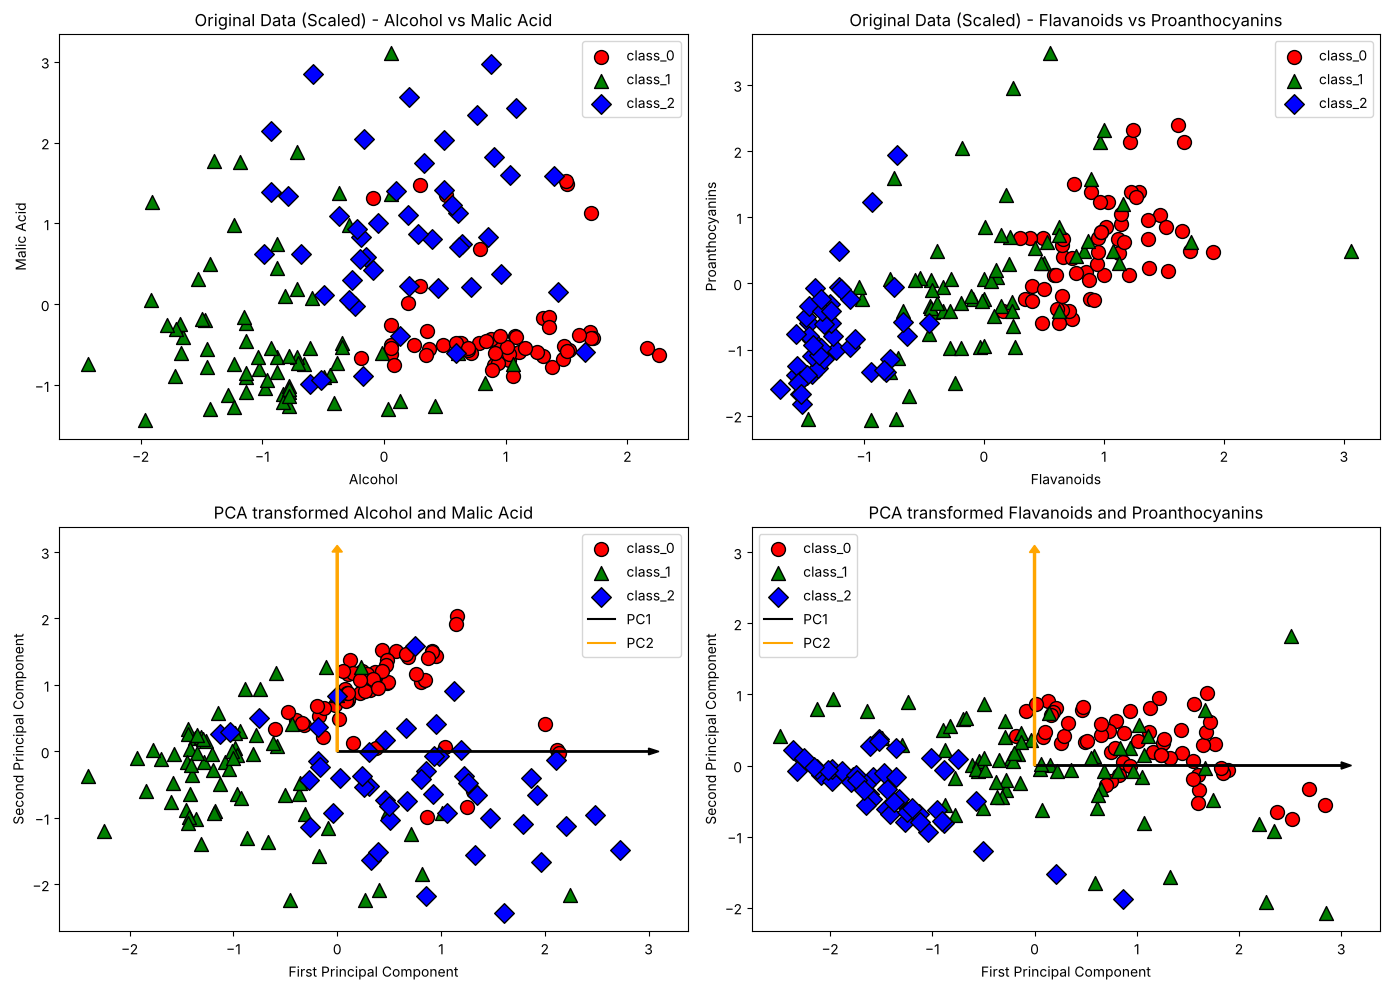

In [ ]:
# Choose two features: 'alcohol' and 'malic_acid'
features_1 = ['alcohol', 'malic_acid']
df_wine_subset_1 = df_wine[features_1]
df_wine_subset_1 = pd.DataFrame(StandardScaler().fit_transform(df_wine_subset_1), columns=features_1)

# Perform PCA on the two features
pca_2d_1 = PCA(n_components=2)
X_pca_2d_1 = pca_2d_1.fit_transform(df_wine_subset_1)

# Choose two different features: 'flavanoids' and 'proanthocyanins'
features_2 = ['flavanoids', 'proanthocyanins']
df_wine_subset_2 = df_wine[features_2]
df_wine_subset_2 = pd.DataFrame(StandardScaler().fit_transform(df_wine_subset_2), columns=features_2)

# Perform PCA on the two different features
pca_2d_2 = PCA(n_components=2)
X_pca_2d_2 = pca_2d_2.fit_transform(df_wine_subset_2)

# Create a figure with four subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Original data plot 1 (top left)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[0,0].scatter(df_wine_subset_1['alcohol'][mask],
                     df_wine_subset_1['malic_acid'][mask],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[0,0].set_xlabel('Alcohol')
axes[0,0].set_ylabel('Malic Acid')
axes[0,0].set_title('Original Data (Scaled) - Alcohol vs Malic Acid')
axes[0,0].legend()

# Original data plot 2 (top right)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[0,1].scatter(df_wine_subset_2['flavanoids'][mask],
                     df_wine_subset_2['proanthocyanins'][mask],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[0,1].set_xlabel('Flavanoids')
axes[0,1].set_ylabel('Proanthocyanins')
axes[0,1].set_title('Original Data (Scaled) - Flavanoids vs Proanthocyanins')
axes[0,1].legend()

# PCA plot 1 (bottom left)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[1,0].scatter(X_pca_2d_1[mask, 0],
                     X_pca_2d_1[mask, 1],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[1,0].set_xlabel('First Principal Component')
axes[1,0].set_ylabel('Second Principal Component')
axes[1,0].set_title('PCA transformed Alcohol and Malic Acid')

# Plot the principal components as vectors for the first PCA plot
origin_1 = np.zeros(2)
components_1 = np.eye(2)
arrow_colors_1 = ['black', 'orange']
scaling = 3
for i, component in enumerate(components_1):
    axes[1,0].arrow(origin_1[0], origin_1[1], component[0] * scaling, component[1] * scaling,
                    color=arrow_colors_1[i], width=0.02, head_width=0.1, head_length=0.1)
    axes[1,0].plot([], [], color=arrow_colors_1[i], label=f'PC{i+1}')

axes[1,0].legend()

# PCA plot 2 (bottom right)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = target_wine == i
    axes[1,1].scatter(X_pca_2d_2[mask, 0],
                     X_pca_2d_2[mask, 1],
                     marker=shape, c=color, edgecolor='k', s=100,
                     label=wine.target_names[i])
axes[1,1].set_xlabel('First Principal Component')
axes[1,1].set_ylabel('Second Principal Component')
axes[1,1].set_title('PCA transformed Flavanoids and Proanthocyanins')

# Plot the principal components as vectors for the second PCA plot
origin_2 = np.zeros(2)
components_2 = np.eye(2)
for i, component in enumerate(components_2):
    axes[1,1].arrow(origin_2[0], origin_2[1], component[0] * scaling, component[1] * scaling,
                    color=arrow_colors_1[i], width=0.02, head_width=0.1, head_length=0.1)
    axes[1,1].plot([], [], color=arrow_colors_1[i], label=f'PC{i+1}')

axes[1,1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Seberapa besar varians yang ditangkap PC1 pada masing-masing pasangan?
for feats, p in [(features_1, pca_2d_1), (features_2, pca_2d_2)]:
    r = df_wine[feats].corr().iloc[0, 1]
    print(f'{feats}: korelasi r = {r:.3f} | EVR PC1 = {p.explained_variance_ratio_[0]:.3f} (teori (1+|r|)/2 = {(1+abs(r))/2:.3f})')

['alcohol', 'malic_acid']: korelasi r = 0.094 | EVR PC1 = 0.547 (teori (1+|r|)/2 = 0.547)
['flavanoids', 'proanthocyanins']: korelasi r = 0.653 | EVR PC1 = 0.826 (teori (1+|r|)/2 = 0.826)


**Interpretasi.** Hasil numerik mengonfirmasi teori: untuk dua fitur terstandardisasi, PC1 menangkap tepat $(1+|r|)/2$ dari total varians. Pasangan *flavanoids–proanthocyanins* yang berkorelasi kuat sebagian besar variasinya dapat diringkas oleh satu komponen, sedangkan *alcohol–malic acid* yang korelasinya lemah tidak banyak "terkompresi" — kedua komponennya sama-sama penting.

### Best practice & jebakan umum PCA
- Selalu standardisasi data terlebih dulu (kecuali semua fitur memang bersatuan sama).
- Pilih jumlah komponen dari kurva *cumulative explained variance* (misal 90–95%), atau set `n_components=0.95`.
- Komponen PCA adalah kombinasi linear semua fitur → **sulit diinterpretasikan**. Hindari PCA jika interpretabilitas fitur penting.
- PCA hanya menangkap struktur **linear** dan tidak memakai label, sehingga arah varians terbesar belum tentu arah yang memisahkan kelas.

## Resep 2 — Linear Discriminant Analysis (LDA)

### Teori
Berbeda dengan PCA, LDA **memakai label kelas**. Didefinisikan dua matriks sebaran (*scatter*):

- **Within-class scatter**: $\displaystyle \mathbf{S}_W = \sum_{c=1}^{C}\sum_{\mathbf{x}_i \in c}(\mathbf{x}_i - \boldsymbol{\mu}_c)(\mathbf{x}_i - \boldsymbol{\mu}_c)^\top$
- **Between-class scatter**: $\displaystyle \mathbf{S}_B = \sum_{c=1}^{C} n_c(\boldsymbol{\mu}_c - \boldsymbol{\mu})(\boldsymbol{\mu}_c - \boldsymbol{\mu})^\top$

LDA mencari proyeksi $\mathbf{w}$ yang memaksimalkan **kriteria Fisher**:
$$J(\mathbf{w}) = \frac{\mathbf{w}^\top\mathbf{S}_B\mathbf{w}}{\mathbf{w}^\top\mathbf{S}_W\mathbf{w}}$$
yaitu sebaran **antar-kelas** sebesar mungkin relatif terhadap sebaran **di dalam kelas**. Solusinya adalah vektor eigen dari $\mathbf{S}_W^{-1}\mathbf{S}_B$. Karena rank $\mathbf{S}_B$ paling banyak $C-1$, LDA menghasilkan **maksimal $C-1$ komponen** — untuk Wine (3 kelas) maksimal 2.

**Asumsi** (agar LDA optimal sebagai classifier): setiap kelas berdistribusi normal multivariat dengan **matriks kovarians yang sama**. Pelanggaran asumsi tidak membuat LDA gagal total, tetapi hasilnya bisa suboptimal.

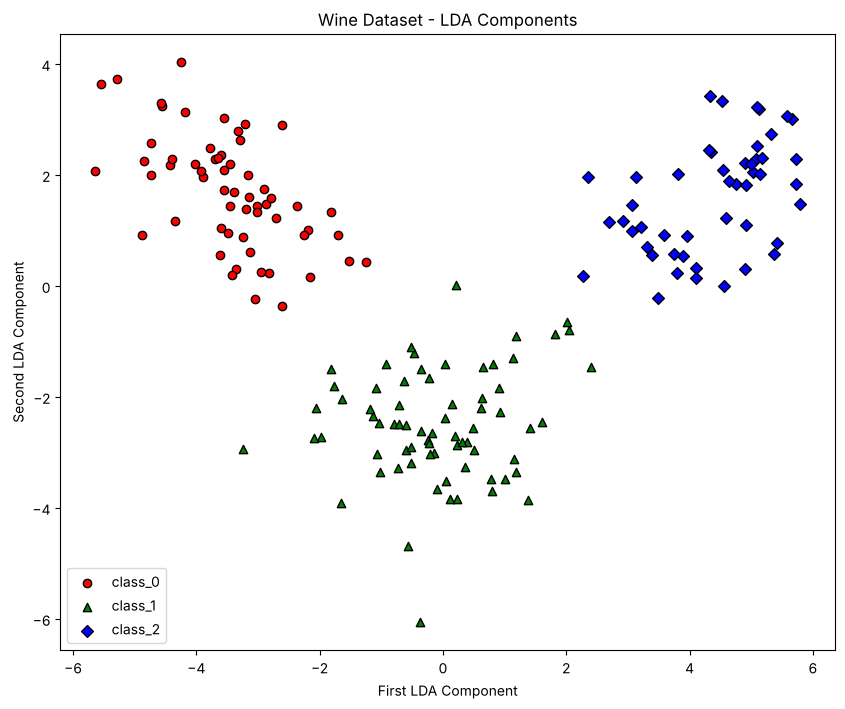

In [ ]:
# Load libraries
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Split wine dataset by features and target
X_wine, y_wine = wine.data, wine.target

# Create LDA pipeline for wine dataset
lda_pipeline_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2))  # min(n_features, n_classes - 1) for wine dataset is 2
])

# Fit and transform the wine data
X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)

# Visualize LDA transformation for wine dataset
plt.figure(figsize=(10, 8))

# Define markers and colors for each class
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

# Plot each class with different marker and color
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.show()

### Perbandingan PCA vs LDA

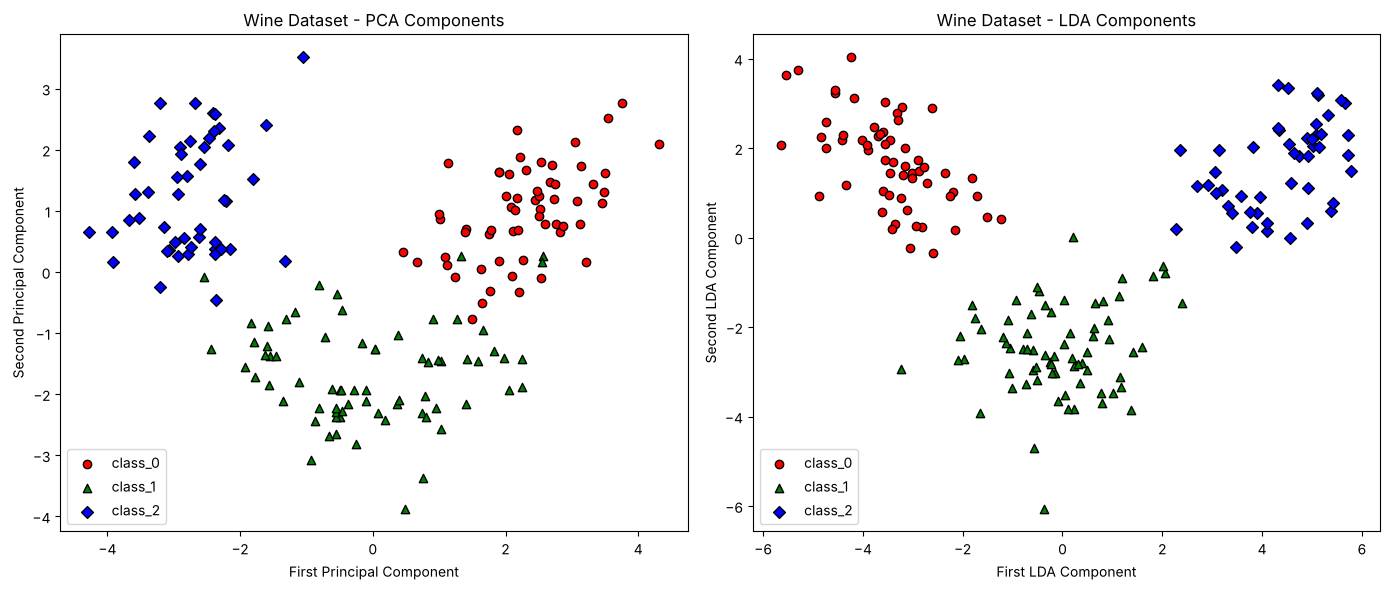

In [ ]:
# Create side-by-side plots
plt.figure(figsize=(14, 6))

plt.subplot(121)
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - PCA Components')
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
               c=color, marker=shape, edgecolor='black',
               label=wine.target_names[i])

plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Ukur pemisahan kelas secara kuantitatif dengan silhouette score (makin tinggi makin terpisah)
from sklearn.metrics import silhouette_score
print('Silhouette (label asli) di ruang PCA: %.3f' % silhouette_score(X_pca, y_wine))
print('Silhouette (label asli) di ruang LDA: %.3f' % silhouette_score(X_lda_wine, y_wine))
lda = lda_pipeline_wine.named_steps['lda']
print('Rasio varians antar-kelas per komponen LDA:', lda.explained_variance_ratio_.round(3))

Silhouette (label asli) di ruang PCA: 0.526
Silhouette (label asli) di ruang LDA: 0.663
Rasio varians antar-kelas per komponen LDA: [0.687 0.313]


**Interpretasi.** Kedua proyeksi sama-sama memperlihatkan tiga kelompok, tetapi LDA menghasilkan kelompok yang lebih rapat dan lebih terpisah, dan ini terlihat dari silhouette score yang lebih tinggi di ruang LDA. Hal ini sesuai dengan tujuannya: PCA memaksimalkan varians **total** tanpa melihat label, sedangkan LDA secara eksplisit memaksimalkan **pemisahan antar-kelas**. Konsekuensinya, LDA hanya bisa dipakai bila label tersedia, dan dengan dataset kecil LDA juga lebih rawan overfitting ke data latih.

### Best practice & jebakan umum LDA
- Scaling tidak mengubah hasil klasifikasi LDA secara teori, tetapi tetap membantu kestabilan numerik.
- Hati-hati bila kelas sangat tidak seimbang atau kovarians antar-kelas sangat berbeda (pertimbangkan QDA).
- Jumlah komponen dibatasi $\min(p, C-1)$.

## Resep 3 — t-SNE untuk Visualisasi Data

### Teori
**t-distributed Stochastic Neighbor Embedding** (van der Maaten & Hinton, 2008) adalah metode **non-linear** yang berfokus mempertahankan **ketetanggaan lokal**.

1. Di ruang asal, kemiripan titik $j$ terhadap $i$ dimodelkan dengan Gaussian:
$$p_{j|i} = \frac{\exp(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert\mathbf{x}_i-\mathbf{x}_k\rVert^2/2\sigma_i^2)}, \qquad p_{ij} = \frac{p_{j|i}+p_{i|j}}{2n}$$
Lebar $\sigma_i$ dipilih agar *perplexity* $2^{H(P_i)}$ sama dengan nilai yang ditentukan (default 30) — kira-kira "jumlah tetangga efektif".
2. Di ruang 2D, kemiripan dimodelkan dengan **distribusi Student-t** (1 derajat bebas), yang ekornya lebih tebal:
$$q_{ij} = \frac{(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2)^{-1}}{\sum_{k\ne l}(1+\lVert\mathbf{y}_k-\mathbf{y}_l\rVert^2)^{-1}}$$
Ekor tebal ini mengatasi *crowding problem*: titik yang tidak mirip bisa ditempatkan jauh.
3. Posisi $\mathbf{y}_i$ dicari dengan *gradient descent* untuk meminimalkan **divergensi Kullback–Leibler**:
$$C = \mathrm{KL}(P\,\Vert\,Q) = \sum_{i\ne j} p_{ij}\log\frac{p_{ij}}{q_{ij}}$$

**Hal penting:** jarak antar-cluster dan ukuran cluster pada plot t-SNE **tidak bermakna** secara kuantitatif; yang bermakna adalah titik mana yang berdekatan. t-SNE juga tidak punya method `transform()` untuk data baru, sehingga hanya cocok untuk **visualisasi**, bukan sebagai langkah preprocessing dalam pipeline model prediktif.

### Persiapan — dataset Digits
1.797 gambar angka tulisan tangan 0–9 berukuran 8×8 piksel → 64 fitur, nilai piksel 0–16.

In [ ]:
# Load libraries
from sklearn.datasets import load_digits

# Load dataset
digits = load_digits()

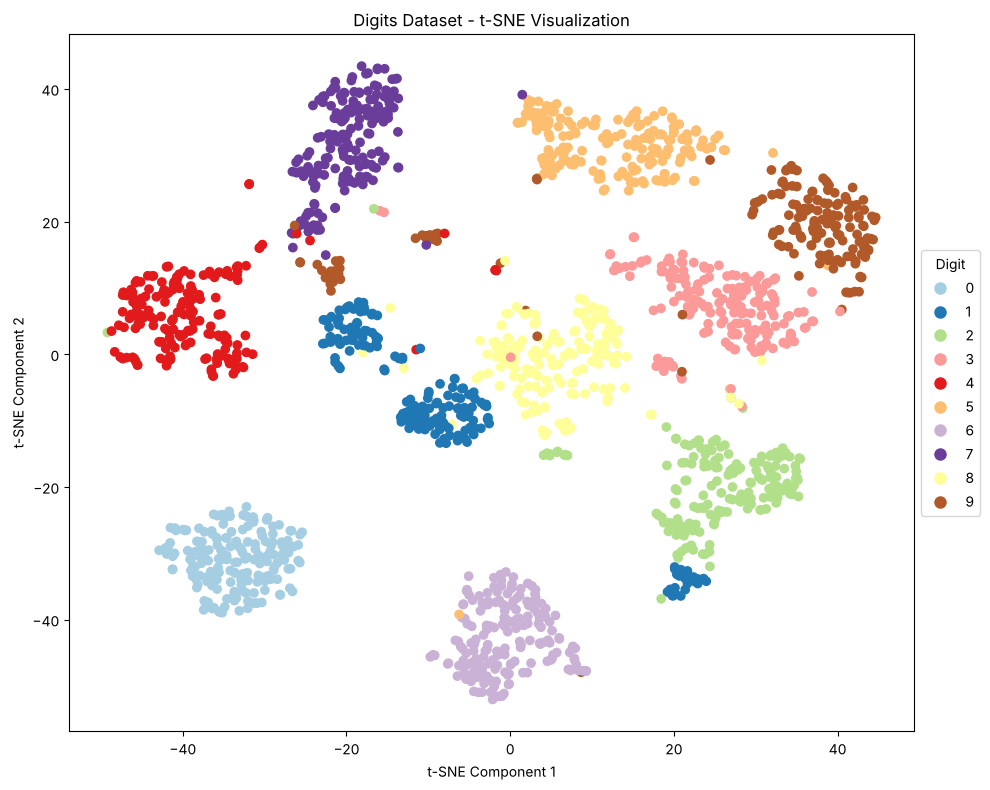

In [ ]:
# Load libraries
from sklearn.manifold import TSNE

# Create t-SNE pipeline
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024))
])

# Fit and transform the digits data
X_tsne = tsne_pipeline.fit_transform(digits.data)
# Visualize t-SNE results
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired', label=digits.target)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('Digits Dataset - t-SNE Visualization')

# Create legend
legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                             markerfacecolor=plt.cm.Paired(i/9),
                             label=str(i), markersize=10)
                  for i in range(10)]
plt.legend(handles=legend_elements, title='Digit', loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

**Interpretasi.** Hampir setiap digit membentuk "pulau" yang terpisah di peta 2D, padahal t-SNE **tidak pernah melihat label** — warna hanya ditambahkan setelahnya. Ini menunjukkan bahwa di ruang 64 dimensi, gambar dari digit yang sama memang saling berdekatan. Beberapa titik yang "menyasar" ke pulau lain biasanya adalah tulisan tangan yang ambigu (misalnya 1 vs 7, atau 3 vs 8 vs 9).

### Best practice & jebakan umum t-SNE
- Coba beberapa nilai `perplexity` (5–50); hasil bisa berbeda cukup jauh.
- Jangan menafsirkan jarak antar-cluster, ukuran cluster, atau kepadatan.
- Untuk dataset sangat besar, umumnya PCA dulu ke ~50 dimensi baru t-SNE (lebih cepat dan mengurangi noise).

## Latihan Praktik

### Latihan 1 — PCA + Logistic Regression
Membandingkan klasifikasi digit dengan seluruh 64 fitur vs fitur hasil PCA yang mempertahankan 95% varians (`n_components=0.95`).

In [ ]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=2024
)

# Pipeline without PCA
pipeline_no_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Pipeline with PCA
pipeline_with_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95)),  # Keep 95% of variance
    ('clf', LogisticRegression(max_iter=1000))
])

# Fit and evaluate both pipelines
pipeline_no_pca.fit(X_train, y_train)
pipeline_with_pca.fit(X_train, y_train)

# Print results
print("Accuracy without PCA:",
      accuracy_score(y_test, pipeline_no_pca.predict(X_test)))
print("Accuracy with PCA:",
      accuracy_score(y_test, pipeline_with_pca.predict(X_test)))

Accuracy without PCA: 0.975
Accuracy with PCA: 0.9638888888888889


In [ ]:
n_comp = pipeline_with_pca.named_steps['pca'].n_components_
print(f'Jumlah komponen PCA untuk 95% varians: {n_comp} dari 64 fitur ({n_comp/64:.0%})')

Jumlah komponen PCA untuk 95% varians: 39 dari 64 fitur (61%)


**Interpretasi.** Untuk mempertahankan 95% varians hanya dibutuhkan 39 komponen dari 64 fitur (≈61%). Akurasi turun sedikit, dari 0,975 menjadi ≈0,964 (sekitar 4 gambar tambahan salah dari 360 gambar uji). Ini *trade-off* klasik PCA: model lebih kecil dan lebih cepat dengan kehilangan akurasi yang kecil. Pada data dengan banyak fitur yang berisi noise, PCA bahkan bisa **menaikkan** akurasi karena berfungsi sebagai penyaring noise.

### Latihan 2 — t-SNE untuk visualisasi hasil clustering
K-Means (10 cluster) dijalankan pada data asli 64 dimensi, lalu hasilnya diwarnai di atas peta t-SNE dan dibandingkan dengan label asli.

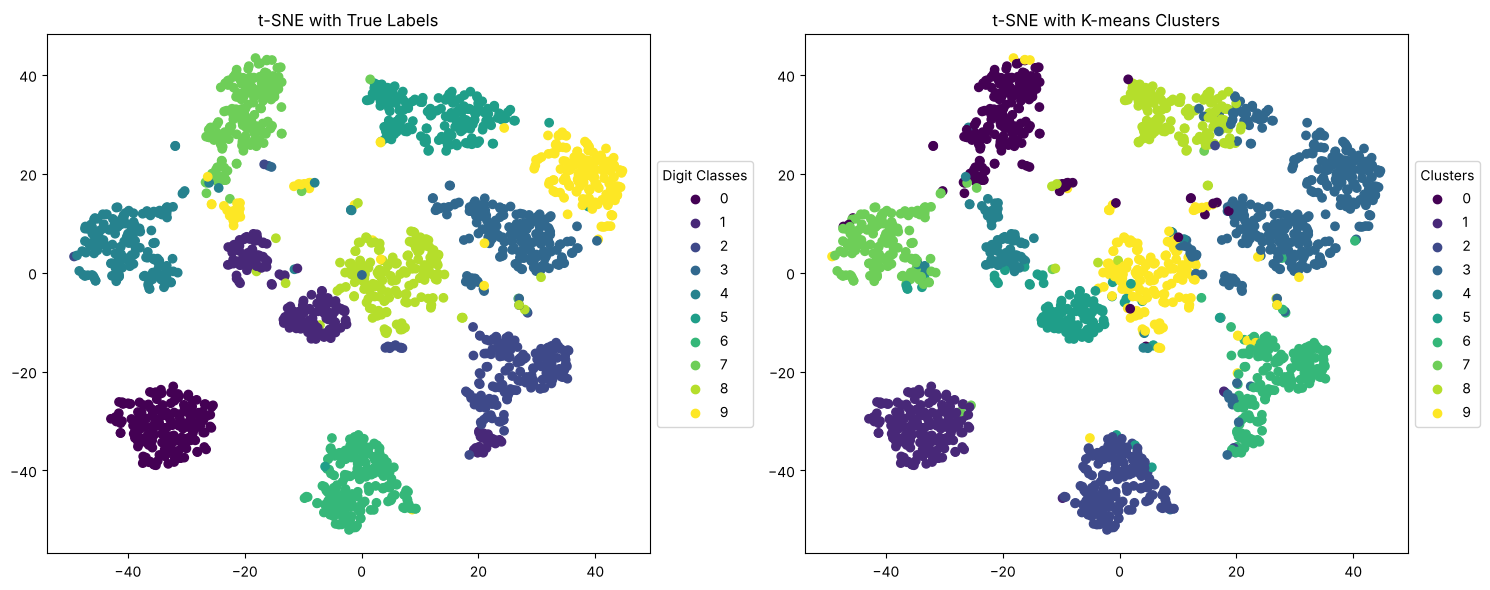

In [ ]:
# Load libraries
from sklearn.cluster import KMeans

# Apply K-means clustering
kmeans = KMeans(n_clusters=10, random_state=2024)
cluster_labels = kmeans.fit_predict(digits.data)

# Create side-by-side plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot using true labels
scatter1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=digits.target, cmap='viridis')
ax1.set_title('t-SNE with True Labels')
legend1 = ax1.legend(*scatter1.legend_elements(),
                    title="Digit Classes",
                    loc="center left",
                    bbox_to_anchor=(1, 0.5))

# Plot using cluster labels
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=cluster_labels, cmap='viridis')
ax2.set_title('t-SNE with K-means Clusters')
legend2 = ax2.legend(*scatter2.legend_elements(),
                    title="Clusters",
                    loc="center left",
                    bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import adjusted_rand_score
print('Adjusted Rand Index (K-Means vs label asli): %.3f' % adjusted_rand_score(digits.target, cluster_labels))

Adjusted Rand Index (K-Means vs label asli): 0.657


**Interpretasi.** Nomor cluster K-Means bersifat arbitrer (cluster 3 tidak berarti digit 3), sehingga yang dibandingkan adalah **pola pengelompokannya**. Sebagian besar pulau t-SNE berisi satu cluster K-Means, menandakan K-Means menemukan kelompok yang mirip dengan digit sebenarnya, tetapi ada pulau yang terbelah atau tergabung. *Adjusted Rand Index* (ARI) mengukur kecocokan dua pengelompokan: 1 = identik, ≈0 = setara acak. Nilainya yang jauh di atas 0 namun di bawah 1 menunjukkan kecocokan yang cukup baik tetapi tidak sempurna. Ini wajar karena K-Means mengasumsikan cluster berbentuk bulat dengan ukuran serupa di ruang 64 dimensi.

## Kesimpulan Bab 3

| | PCA | LDA | t-SNE |
|---|---|---|---|
| Butuh label? | Tidak | **Ya** | Tidak |
| Linear? | Ya | Ya | **Tidak** |
| Tujuan | varians maksimum | pemisahan kelas maksimum | mempertahankan tetangga lokal |
| Jumlah komponen | ≤ p | ≤ C − 1 | biasanya 2–3 |
| Bisa `transform` data baru? | Ya | Ya | **Tidak** |
| Kegunaan utama | kompresi, denoising, preprocessing | preprocessing klasifikasi, visualisasi | visualisasi |

- Standardisasi data sebelum reduksi dimensi.
- PCA bisa memangkas fitur secara signifikan dengan penurunan akurasi yang kecil (pada Digits: 64 → 39 fitur, akurasi 0,975 → 0,964).
- LDA memanfaatkan label sehingga lebih baik dalam memisahkan kelas; t-SNE sangat baik untuk eksplorasi visual tetapi jaraknya tidak boleh diinterpretasikan secara global.